# TP6. Géométrie du plan

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp6-geometrie-plan/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : la boîte à outils

Écrivez `vecteur(A, B)`, `produit_scalaire(u, v)`, `norme(u)` et `angle(u, v)`, ce
dernier en degrés.

**Résultat attendu :** `norme((3, 4))` vaut `5.0`, `produit_scalaire((1, 2), (3, 4))`
vaut `11`, `angle((1, 0), (1, 1))` vaut `45.0` à l'arrondi près, et
`angle((1, 0), (0, 1))` vaut `90.0`.


In [1]:
import math

def vecteur(A, B):
    """Vecteur AB, de A vers B."""
    return (B[0] - A[0], B[1] - A[1])

def produit_scalaire(u, v):
    """Produit scalaire de u et v."""
    return u[0] * v[0] + u[1] * v[1]

def norme(u):
    """Norme de u (hypot évite de faire déborder les carrés)."""
    return math.hypot(u[0], u[1])

def angle(u, v):
    """Angle non orienté entre u et v, en degrés."""
    c = produit_scalaire(u, v) / (norme(u) * norme(v))
    c = max(-1.0, min(1.0, c))
    return math.degrees(math.acos(c))

print(norme((3, 4)), produit_scalaire((1, 2), (3, 4)))
print(angle((1, 0), (1, 1)), angle((1, 0), (0, 1)))
print(angle((2, 0), (2, 0)))

# pourquoi le max/min : deux vecteurs parallèles, et le cosinus dépasse 1
u, v = (0.1, 0.1), (0.2, 0.2)
c = produit_scalaire(u, v) / (norme(u) * norme(v))
print(c)
try:
    math.acos(c)
except ValueError as e:
    print("acos sans protection :", e)

# et pourquoi hypot
print(math.sqrt(1e200 * 1e200 + 1e200 * 1e200), math.hypot(1e200, 1e200))

5.0 11
45.00000000000001 90.0
0.0
1.0000000000000002
acos sans protection : math domain error
inf 1.414213562373095e+200


## Exercice 1.2 : la distance d'un point à une droite

La distance du point $P$ à la droite $(AB)$ vaut
$\dfrac{|\vec{AB} \times \vec{AP}|}{\|\vec{AB}\|}$, où $\times$ désigne le
**déterminant** $u_x v_y - u_y v_x$, que l'étape suivante interprète. Écrivez
`determinant(u, v)` puis `distance_point_droite(P, A, B)`.

**Résultat attendu :** la distance de l'origine à la droite passant par $(0, 1)$ et
$(1, 0)$ vaut $\sqrt{2}/2 \approx 0{,}7071$, et celle de $(3, 4)$ à l'axe des
abscisses vaut `4.0`.


In [2]:
def determinant(u, v):
    """Déterminant de (u, v) : aire orientée du parallélogramme construit sur u et v."""
    return u[0] * v[1] - u[1] * v[0]

def distance_point_droite(P, A, B):
    """Distance de P à la droite (AB)."""
    if A == B:
        raise ValueError("A et B confondus : pas de droite")
    AB = vecteur(A, B)
    return abs(determinant(AB, vecteur(A, P))) / norme(AB)

print(distance_point_droite((0, 0), (0, 1), (1, 0)), math.sqrt(2) / 2)
print(distance_point_droite((3, 4), (0, 0), (1, 0)))
# un point de la droite est à distance nulle
print(distance_point_droite((0.5, 0.5), (0, 1), (1, 0)))

0.7071067811865475 0.7071067811865476
4.0
0.0


## Exercice 2.1 : à gauche ou à droite ?

Écrivez `orientation(A, B, C)` qui renvoie `1` si le trajet $A \to B \to C$ tourne
à gauche, `-1` s'il tourne à droite, `0` si les trois points sont alignés.

**Résultat attendu :** `orientation((0, 0), (1, 0), (1, 1))` vaut `1`,
`orientation((0, 0), (1, 0), (1, -1))` vaut `-1`, et
`orientation((0, 0), (1, 1), (2, 2))` vaut `0`.


In [3]:
def orientation(A, B, C):
    """1 si A -> B -> C tourne à gauche, -1 à droite, 0 si alignés."""
    d = determinant(vecteur(A, B), vecteur(A, C))
    if d > 0:
        return 1
    if d < 0:
        return -1
    return 0

print(orientation((0, 0), (1, 0), (1, 1)))
print(orientation((0, 0), (1, 0), (1, -1)))
print(orientation((0, 0), (1, 1), (2, 2)))

1
-1
0


In [4]:
from fractions import Fraction

# trois points de la droite y = 3x
A, B, C = (0.1, 0.3), (0.3, 0.9), (0.7, 2.1)
print("flottants :", determinant(vecteur(A, B), vecteur(A, C)), orientation(A, B, C))

# les mêmes, avec les valeurs exactes que la machine a stockées
Ae, Be, Ce = [(Fraction(x), Fraction(y)) for x, y in (A, B, C)]
print("valeurs stockées, calcul exact :", determinant(vecteur(Ae, Be), vecteur(Ae, Ce)))

flottants : -5.551115123125783e-17 -1
valeurs stockées, calcul exact : 0


Les trois flottants stockés sont **exactement** alignés (le déterminant calculé avec
des `Fraction` vaut 0), mais le calcul en flottants donne `-5.55e-17` et donc
`orientation = -1` : la machine dit « à droite » pour trois points alignés. L'erreur ne vient
pas des données, elle vient des soustractions dans `vecteur` et `determinant`.

## Exercice 2.2 : l'aire d'un polygone

Un polygone est une liste de sommets dans l'ordre. Son aire vaut la moitié de la
valeur absolue de la somme des déterminants $x_i y_{i+1} - x_{i+1} y_i$ sur les
côtés consécutifs, le dernier sommet étant relié au premier : c'est la **formule du
lacet**. Écrivez `aire(polygone)`.

**Résultat attendu :** le carré unité a une aire de `1.0`, le triangle
$(0,0), (4,0), (0,3)$ une aire de `6.0`, et la maison du TP4,
`[(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]`, une aire de `4.0`.


In [5]:
def aire(polygone):
    """Aire d'un polygone simple, sommets donnés dans l'ordre (formule du lacet)."""
    s = 0
    n = len(polygone)
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        s = s + (x1 * y2 - x2 * y1)
    return abs(s) / 2

carre = [(0, 0), (1, 0), (1, 1), (0, 1)]
triangle = [(0, 0), (4, 0), (0, 3)]
maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]
print(aire(carre), aire(triangle), aire(maison))

# sans la valeur absolue, le signe donne le sens de parcours
def aire_orientee(polygone):
    n = len(polygone)
    return sum(polygone[i][0] * polygone[(i + 1) % n][1] - polygone[(i + 1) % n][0] * polygone[i][1]
               for i in range(n)) / 2

print(aire_orientee(maison), aire_orientee(maison[::-1]))

1.0 6.0 4.0
4.0 -4.0


## Exercice 3.1 : le test de croisement

Écrivez `se_coupent(A, B, C, D)` avec quatre appels à `orientation`. Ne traitez pas les
cas où trois points sont alignés : renvoyez `False`, et notez-le dans la docstring.

**Résultat attendu :** les diagonales du carré unité se coupent ; les segments
$[(0,0), (1, 0)]$ et $[(0, 1), (1, 1)]$, parallèles, ne se coupent pas ;
$[(0,0), (1,1)]$ et $[(2,2), (3,3)]$, alignés mais disjoints, non plus.


In [6]:
def se_coupent(A, B, C, D):
    """Vrai si les segments [AB] et [CD] se croisent franchement.

    Les cas dégénérés (trois points alignés) renvoient False.
    """
    o1 = orientation(A, B, C)
    o2 = orientation(A, B, D)
    o3 = orientation(C, D, A)
    o4 = orientation(C, D, B)
    return o1 * o2 < 0 and o3 * o4 < 0

print(se_coupent((0, 0), (1, 1), (0, 1), (1, 0)))
print(se_coupent((0, 0), (1, 0), (0, 1), (1, 1)))
print(se_coupent((0, 0), (1, 1), (2, 2), (3, 3)))
# un T : C est sur [AB], cas dégénéré
print(se_coupent((0, 0), (2, 0), (1, 0), (1, 1)))

True
False
False
False


## Exercice 3.2 : le point d'intersection

Quand les segments se coupent, on veut souvent le point. En écrivant
$A + t\,\vec{AB} = C + u\,\vec{CD}$, on obtient un système de deux équations à deux
inconnues $t$ et $u$, que les déterminants résolvent directement :
$t = \dfrac{\vec{AC} \times \vec{CD}}{\vec{AB} \times \vec{CD}}$ et
$u = \dfrac{\vec{AC} \times \vec{AB}}{\vec{AB} \times \vec{CD}}$. Écrivez
`intersection(A, B, C, D)` qui renvoie le point, ou `None` si les segments ne se
coupent pas.

**Résultat attendu :** les diagonales du carré de côté 2 se coupent en `(1.0, 1.0)`.


In [7]:
import random

def intersection(A, B, C, D):
    """Point d'intersection des segments [AB] et [CD], ou None."""
    AB = vecteur(A, B)
    CD = vecteur(C, D)
    den = determinant(AB, CD)
    if den == 0:
        return None  # parallèles ou alignés
    AC = vecteur(A, C)
    t = determinant(AC, CD) / den
    u = determinant(AC, AB) / den
    if 0 <= t <= 1 and 0 <= u <= 1:
        return (A[0] + t * AB[0], A[1] + t * AB[1])
    return None

print(intersection((0, 0), (2, 2), (0, 2), (2, 0)))
print(intersection((0, 0), (1, 0), (0, 1), (1, 1)))
print(intersection((0, 0), (1, 1), (2, 2), (3, 3)))

# les deux méthodes doivent être d'accord sur des segments au hasard
random.seed(3)
desaccords = 0
for _ in range(20_000):
    A, B, C, D = [(random.random(), random.random()) for _ in range(4)]
    if se_coupent(A, B, C, D) != (intersection(A, B, C, D) is not None):
        desaccords += 1
print("désaccords sur 20 000 paires :", desaccords)

(1.0, 1.0)
None
None
désaccords sur 20 000 paires : 0


## Exercice 4.1 : le lancer de rayon

Écrivez `dedans(P, polygone)`. Pour chaque côté $[S_i S_{i+1}]$, le rayon le
traverse si les deux ordonnées encadrent celle de $P$ et si l'abscisse du point de
croisement, obtenue par interpolation, est à droite de $P$.

**Résultat attendu :** dans la maison, `(1, 1)` et `(1, 2.4)` sont dedans, `(3, 1)`
et `(0.2, 2.2)` sont dehors.


In [8]:
def dedans(P, polygone):
    """Vrai si P est à l'intérieur du polygone, par lancer de rayon horizontal."""
    x, y = P
    n = len(polygone)
    res = False
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        if (y1 > y) != (y2 > y):
            xc = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x < xc:
                res = not res
    return res

for P in ((1, 1), (1, 2.4), (3, 1), (0.2, 2.2)):
    print(P, dedans(P, maison))

(1, 1) True
(1, 2.4) True
(3, 1) False
(0.2, 2.2) False


## Exercice 4.2 : l'aire par le hasard

On peut estimer une aire sans formule : tirer des points au hasard dans un rectangle
qui contient la figure, compter ceux qui tombent dedans, et multiplier la proportion
par l'aire du rectangle. C'est la **méthode de Monte-Carlo**. Estimez ainsi l'aire de
la maison avec 200 000 points tirés dans le rectangle $[0, 2] \times [0, 2{,}5]$.

**Résultat attendu :** une valeur proche de `4.0`, à quelques centièmes près, et qui
change à chaque exécution si vous ne fixez pas la graine.


In [9]:
random.seed(0)
tirages = 200_000
touches = 0
for _ in range(tirages):
    P = (random.uniform(0, 2), random.uniform(0, 2.5))
    if dedans(P, maison):
        touches += 1
print(2 * 2.5 * touches / tirages)

# l'erreur en fonction du nombre de tirages
def monte_carlo(polygone, xmin, xmax, ymin, ymax, n):
    """Aire estimée par n tirages uniformes dans le rectangle donné."""
    t = 0
    for _ in range(n):
        if dedans((random.uniform(xmin, xmax), random.uniform(ymin, ymax)), polygone):
            t += 1
    return (xmax - xmin) * (ymax - ymin) * t / n

random.seed(5)
for n in (200, 2_000, 20_000, 200_000):
    print(f"n = {n:>7} : erreur {abs(monte_carlo(maison, 0, 2, 0, 2.5, n) - 4):.4f}")

# un seul essai par ligne, c'est trop irrégulier : on moyenne sur 100 essais
prec = None
for n in (100, 1_000, 10_000):
    e = sum(abs(monte_carlo(maison, 0, 2, 0, 2.5, n) - 4) for _ in range(100)) / 100
    print(f"n = {n:>6} : erreur moyenne {e:.4f}" + (f" | divisée par {prec / e:.1f}" if prec else ""))
    prec = e

3.994425
n =     200 : erreur 0.1250
n =    2000 : erreur 0.0250
n =   20000 : erreur 0.0023


n =  200000 : erreur 0.0015
n =    100 : erreur moyenne 0.1585
n =   1000 : erreur moyenne 0.0518 | divisée par 3.1


n =  10000 : erreur moyenne 0.0161 | divisée par 3.2


Avec un seul essai par valeur de `n`, l'erreur ne décroît pas régulièrement : elle est
elle-même aléatoire, et on peut tomber près de 4 par chance. En moyennant sur 100 essais,
elle est divisée par environ 3 quand `n` est multiplié par 10, ce qui correspond au
$1/\sqrt{N}$ annoncé ($\sqrt{10} \approx 3{,}2$).

## Exercice 5.1 : un polygone qui n'est pas convexe

Construisez un polygone en forme de L ou d'étoile, non convexe, et vérifiez sur un
tracé que `dedans` et `aire` donnent des résultats corrects, y compris dans le creux.


5.0 attendu 5
(0.5, 2) True
(2, 0.5) True
(2, 2) False
(2.5, 2.5) False
(0.5, 0.5) True
(1.5, 1.5) False
Monte-Carlo : 4.99275


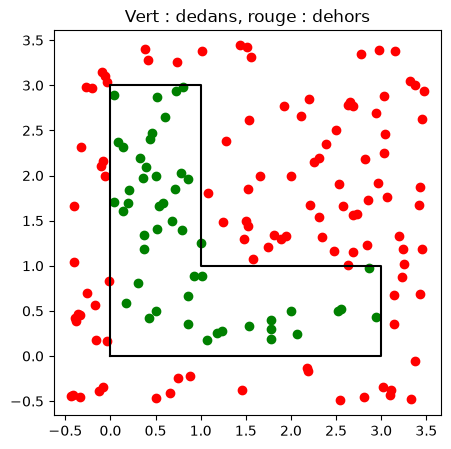

In [10]:
import matplotlib.pyplot as plt

def tracer_polygone(polygone, points=()):
    xs = [s[0] for s in polygone] + [polygone[0][0]]
    ys = [s[1] for s in polygone] + [polygone[0][1]]
    plt.figure(figsize=(5, 5))
    plt.plot(xs, ys, color="black")
    for P in points:
        couleur = "green" if dedans(P, polygone) else "red"
        plt.scatter([P[0]], [P[1]], color=couleur)
    plt.axis("equal")
    plt.title("Vert : dedans, rouge : dehors")
    plt.show()

# un L : rectangle 3 x 1 en bas, rectangle 1 x 2 au-dessus à gauche
L = [(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)]
print(aire(L), "attendu", 3 * 1 + 1 * 2)

tests = [(0.5, 2), (2, 0.5), (2, 2), (2.5, 2.5), (0.5, 0.5), (1.5, 1.5)]
for P in tests:
    print(P, dedans(P, L))

random.seed(2)
print("Monte-Carlo :", monte_carlo(L, 0, 3, 0, 3, 100_000))

random.seed(1)
nuage = [(random.uniform(-0.5, 3.5), random.uniform(-0.5, 3.5)) for _ in range(150)]
tracer_polygone(L, nuage + tests)

L'aire vaut 5 comme la décomposition en deux rectangles, et Monte-Carlo retrouve à peu
près 5. Dans le creux du L, `(2, 2)`, `(2.5, 2.5)` et `(1.5, 1.5)` sont dehors : le rayon
horizontal partant de ces points vers la droite ne traverse aucun côté. Sur le tracé, aucun
point vert ne tombe dans le creux.

## Exercice 6.1 : le polygone le plus proche

On dispose de plusieurs polygones, par exemple les zones d'une carte, et d'un point
cliqué. Écrivez `zone_de(P, zones)` qui renvoie l'indice de la zone contenant `P`, ou
`None`. Testez avec la maison et le carré `[(3, 0), (4, 0), (4, 1), (3, 1)]`.

**Résultat attendu :** `(1, 1)` est dans la zone `0`, `(3.5, 0.5)` dans la zone `1`,
`(2.5, 0.5)` dans aucune.


In [11]:
def zone_de(P, zones):
    """Indice de la première zone qui contient P, ou None."""
    for i, zone in enumerate(zones):
        if dedans(P, zone):
            return i
    return None

zones = [maison, [(3, 0), (4, 0), (4, 1), (3, 1)]]
for P in ((1, 1), (3.5, 0.5), (2.5, 0.5)):
    print(P, zone_de(P, zones))

(1, 1) 0
(3.5, 0.5) 1
(2.5, 0.5) None


In [12]:
import time

# beaucoup de petites zones : on écarte d'abord celles dont le rectangle englobant
# ne contient pas le point
def boite(zone):
    xs = [s[0] for s in zone]
    ys = [s[1] for s in zone]
    return min(xs), max(xs), min(ys), max(ys)

def zone_de_rapide(P, zones, boites):
    """Comme zone_de, mais on ne lance le rayon que si P est dans la boîte englobante."""
    x, y = P
    for i, (zone, (x1, x2, y1, y2)) in enumerate(zip(zones, boites)):
        if x1 <= x <= x2 and y1 <= y <= y2 and dedans(P, zone):
            return i
    return None

random.seed(4)
grandes = []
for _ in range(2000):
    x, y = random.uniform(0, 100), random.uniform(0, 100)
    grandes.append([(x, y), (x + 1, y), (x + 1, y + 1), (x, y + 1)])
boites = [boite(z) for z in grandes]
clics = [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(500)]

t0 = time.perf_counter()
r1 = [zone_de(P, grandes) for P in clics]
t1 = time.perf_counter() - t0
t0 = time.perf_counter()
r2 = [zone_de_rapide(P, grandes, boites) for P in clics]
t2 = time.perf_counter() - t0
print(r1 == r2, f"sans boîte {t1:.3f} s | avec boîte {t2:.3f} s | rapport {t1 / t2:.1f}")

True sans boîte 0.508 s | avec boîte 0.093 s | rapport 5.5


## Pour aller plus loin : l'enveloppe convexe

Algorithme d'Andrew : on trie les points, puis on construit la chaîne du bas et celle du
haut en enlevant le dernier point tant que le virage n'est pas à gauche.

[(0, 0), (1, 0), (1, 1), (0, 1)]
8 sommets, aire 22.174 sens direct : True
True


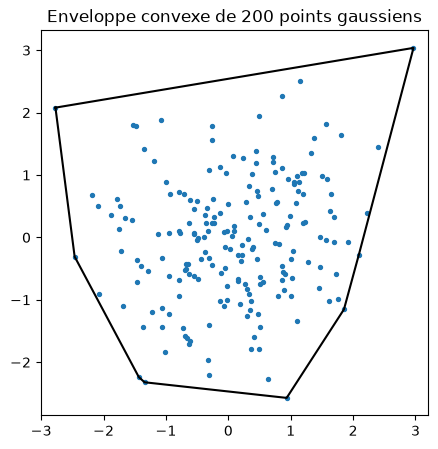

In [13]:
def enveloppe(points):
    """Enveloppe convexe (algorithme d'Andrew), sommets dans le sens direct."""
    pts = sorted(set(points))
    if len(pts) <= 2:
        return pts
    bas = []
    for P in pts:
        while len(bas) >= 2 and orientation(bas[-2], bas[-1], P) <= 0:
            bas.pop()
        bas.append(P)
    haut = []
    for P in reversed(pts):
        while len(haut) >= 2 and orientation(haut[-2], haut[-1], P) <= 0:
            haut.pop()
        haut.append(P)
    return bas[:-1] + haut[:-1]

print(enveloppe(carre + [(0.5, 0.5)]))

random.seed(6)
gauss = [(random.gauss(0, 1), random.gauss(0, 1)) for _ in range(200)]
E = enveloppe(gauss)
print(len(E), "sommets, aire", round(aire(E), 3), "sens direct :", aire_orientee(E) > 0)

# vérification : aucun point n'est à droite d'un côté de l'enveloppe
n = len(E)
print(all(orientation(E[i], E[(i + 1) % n], P) >= 0 for i in range(n) for P in gauss))

xs = [s[0] for s in E] + [E[0][0]]
ys = [s[1] for s in E] + [E[0][1]]
plt.figure(figsize=(5, 5))
plt.scatter([p[0] for p in gauss], [p[1] for p in gauss], s=8)
plt.plot(xs, ys, color="black")
plt.axis("equal")
plt.title("Enveloppe convexe de 200 points gaussiens")
plt.show()

## L'IA vous le donne en trois secondes

**Point dans un polygone.** J'ai posé la question à un assistant IA, puis j'ai exécuté le code qu'il proposait pour vérifier ses affirmations.

In [14]:
# la fonction proposée (recopiée telle quelle)
def point_dans_polygone(point, polygone):
    x, y = point
    inside = False
    n = len(polygone)
    j = n - 1
    for i in range(n):
        xi, yi = polygone[i]
        xj, yj = polygone[j]
        if ((yi > y) != (yj > y)) and (x < (xj - xi) * (y - yi) / (yj - yi) + xi):
            inside = not inside
        j = i
    return inside

# la variante qu'on voit aussi souvent : encadrement large des deux côtés
def dedans_large(P, polygone):
    x, y = P
    n = len(polygone)
    res = False
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        if min(y1, y2) <= y <= max(y1, y2) and y1 != y2:
            xc = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x < xc:
                res = not res
    return res

for P in ((1, 1.5), (0.5, 1.5), (1, 0), (0, 1), (2, 1), (1, 2.5)):
    print(P, point_dans_polygone(P, maison), dedans_large(P, maison))

(1, 1.5) True False
(0.5, 1.5) True False
(1, 0) True True
(0, 1) True True
(2, 1) False False
(1, 2.5) False False


Il donne directement la bonne condition, `(yi > y) != (yj > y)`, et `(1, 1.5)` est bien
dedans : le sommet `(2, 1.5)` n'est compté que pour un des deux côtés qui s'y rejoignent.
Ce qu'il ne dit pas, c'est ce qui arrive sur le bord : `(1, 0)` (côté du bas) et `(0, 1)`
(côté gauche) sont « dedans », `(2, 1)` (côté droit) et `(1, 2.5)` (le faîte) sont
« dehors ». C'est une convention cohérente, mais il faut la connaître si deux zones
partagent un côté. La variante avec `min(y1, y2) <= y <= max(y1, y2)` compte le sommet
deux fois et met `(1, 1.5)` et `(0.5, 1.5)` dehors, ce qui est faux.